# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [1]:
# Twoje rozwiązanie

try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)                                   # DatasetDict: train / test / unsupervised
    train_df = imdb["train"].to_pandas()          # kolumny: text, label
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)
train_df.head()

def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)

train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])
print("recenzji z '<br />' po czyszczeniu:", train_df["text"].str.contains("<br />").sum())

class_share = train_df["label"].value_counts(normalize=True)
median_words = train_df["text"].str.split().str.len().median()
print(class_share, median_words)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)
recenzji z '<br />' po czyszczeniu: 0
label
0    0.5
1    0.5
Name: proportion, dtype: float64 173.0


In [2]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

In [4]:
# Twoje rozwiązanie
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000)
}

X_train, y_train = train_df["text"], train_df["label"]

wiersze = []
for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), X_train, y_train, cv=cv, return_train_score=True)
    wiersze.append({"model": nazwa, "CV": r["test_score"].mean(), "CV odch.": r["test_score"].std(),
                    "train": r["train_score"].mean(), "czas uczenia [s]": r["fit_time"].mean()})
porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)

,CV,CV odch.,train,czas uczenia [s]
model,,,,
naiwny Bayes,0.862,0.002,0.916,6.188
liniowy SVM,0.893,0.001,0.993,4.781
regresja logistyczna,0.885,0.002,0.933,5.167


In [5]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

Możemy zaobserwować, poza oczywistym wzrostem czasu uczenia, minimalny wzrost dokładności na zbiorach walidacyjnych oraz mimimalny spadek dokładności na zbiorach treningowych. Kolejnośc modeli względem wyniku CV się niezmieniła.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [6]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV

gs = GridSearchCV(make_pipeline(TfidfVectorizer(min_df=2), LinearSVC()),
                  param_grid={"tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
                              "linearsvc__C": [0.1, 1]},
                  cv=cv)
gs.fit(X_train, y_train)
gs.best_params_, gs.best_score_

gs.cv_results_["mean_fit_time"]

array([ 4.13111806, 10.84232879,  4.02639723, 11.53851859])

In [7]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

Na pełnym zbiorze, pięciokrotnie większy zbiór względem wzorca, osiągneliśmy rezultaty lepsze niż dla wszystkich poprzednich klasyfikatorów, gdzie we wzorcu obserwowaliśmy porównywalny wynik do pozostałych. Większy zbiór zapewnia częstsze występowanie par słów, co zwiększa ich wpływ na klasyfikowanie.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy (test): 0.903


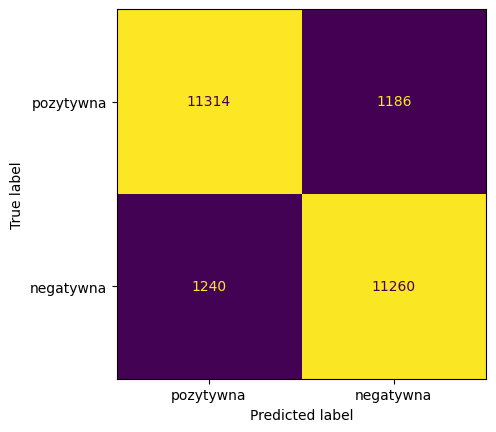

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [8]:
# Twoje rozwiązanie

model_koncowy = gs.best_estimator_
acc_test = model_koncowy.score(test_df["text"], test_df["label"])
print(f"accuracy (test): {acc_test:.3f}")

y_pred = model_koncowy.predict(test_df["text"])
ConfusionMatrixDisplay.from_predictions(test_df["label"], y_pred, display_labels=["pozytywna", "negatywna" ], colorbar=False)
plt.show()
print(classification_report(test_df["label"], y_pred, target_names=["negatywna", "pozytywna"], digits=3))

In [9]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [10]:
# Twoje rozwiązanie
wagi = pd.Series(model_koncowy[-1].coef_[0], index=model_koncowy[0].get_feature_names_out()).sort_values()
display(wagi.head(15))
display(wagi.tail(15))

y_test = test_df["label"]

bledy = test_df.copy()
bledy["pred"] = y_pred
bledy = bledy[bledy["label"] != bledy["pred"]]

print(f"Liczba błędów: {len(bledy)}\n")

for indeks, wiersz in bledy.head(3).iterrows():
    print(f"Indeks: {indeks} | Prawdziwa: {wiersz['label']} | Przewidziana: {wiersz['pred']}")
    display(wiersz["text"][:500])
    print("---------------------------------------------------------------------")

moje_recenzje = [
    # 1. Standardowa pozytywna
    "This movie was absolutely amazing! The story was gripping, the acting was superb, and I enjoyed every single minute of it.",

    # 2. Recenzja z negacją (pozytywna w ogólnym wydźwięku, ale zawierająca negacje)
    "I was expecting a terrible film, but it was not bad at all. Actually, it was not a waste of time, and I did not hate it.",

    # 3. Recenzja ironiczna (słowa są pozytywne, ale sens jest wybitnie negatywny)
    "Oh, what a masterpiece! I absolutely loved sitting in a dark theater for two hours staring at the most boring plot ever written. Truly brilliant."
]

predykcje = model_koncowy.predict(moje_recenzje)
print(predykcje)

,0
worst,-4.186860
awful,-3.717987
bad,-3.639967
boring,-3.461435
poor,-3.270281
the worst,-3.183395
waste,-2.919468
disappointment,-2.604945
terrible,-2.583009
worse,-2.566881


,0
best,1.835280
favorite,1.853958
bit,1.855964
loved,1.876260
superb,1.906072
brilliant,1.945156
the best,1.955428
enjoyable,1.964973
today,2.203576
amazing,2.208378


Liczba błędów: 2426

Indeks: 4 | Prawdziwa: 0 | Przewidziana: 1


"First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other action guys (Segal and Dolph) have thought about putting out the past few years. Van Damme is good in the movie, the movie is only worth watching to Van Damme fans. It is not as good as Wake of Death (whi"

---------------------------------------------------------------------
Indeks: 18 | Prawdziwa: 0 | Przewidziana: 1


"Ben, (Rupert Grint), is a deeply unhappy adolescent, the son of his unhappily married parents. His father, (Nicholas Farrell), is a vicar and his mother, (Laura Linney), is ... well, let's just say she's a somewhat hypocritical soldier in Jesus' army. It's only when he takes a summer job as an assistant to a foul-mouthed, eccentric, once-famous and now-forgotten actress Evie Walton, (Julie Walters), that he finally finds himself in true 'Harold and Maude' fashion. Of course, Evie is deeply unhap"

---------------------------------------------------------------------
Indeks: 32 | Prawdziwa: 0 | Przewidziana: 1


"I'm the type of guy who loves hood movies from New Jack City to Baby Boy to Killa Season, from the b grade to the Hollywood. but this movie was something different. i am no hater and this movie was kinda enjoyable. but some bits were just weird. well the acting wasn't to good, compared to Silkk The Shockers performance in Hot Boyz (quite good) and Ice-T in new Jack and SVU (great). the scene where Corrupt (Ice-T) kills the wanna be Jamaican dude he says something and lights himself on fire burni"

---------------------------------------------------------------------
[1 0 0]


In [11]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?

Znalazł się bigramy "the worst" i "the best". Model potrafi je znaleźć i poprawnie porzypożądkować, poprawiają one przypisania modelu, ale same bigramy nie są tak silne jak pojedyńcze słowa.

2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?

pierwsza i trzecia recenzja zawierają w sobie mieszane odczucia co do filmu, druga w znacznej częsci zawiera opis fabuły samego filmu, nie opinie, stąd w przypadku tych trzech opinii model mógł je źle sklasyfikować ze względu na niejasny kontekst poszczególnych słów. CZłowiek również mógłby mieć problem z ich klasyfikacjią szczególnie dla prostego rozróżnienia pozytywna/negatywan bez ich uważniejszego i pełnego przeanalizowania.

3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?

Model ocenił źle jedynie recenzję 2, pewnie przez niemożliwość poprawnej interpretacji zaprzeczeń negacji wynikającej ze zbyt krótkich ngramów. CO ciekawe poprawnie przypisał negatywną ocenę do 3 recenzji, któa była ironiczna, prawdopodbnie ze względu na wysoką ujemną wagę słowa "boring".

4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

Model musiałby umieć rozpoznać kontekst użytych słów, negacje, sarkazmy.